In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# For better plots
plt.style.use('seaborn-v0_8')


In [5]:
df = pd.read_csv("train.csv")

# View first 5 rows
print(df.head())

# Check structure
print(df.info())

# Summary statistics
print(df.describe())


        text_id                                          full_text  cohesion  \
0  0016926B079C  I think that students would benefit from learn...       3.5   
1  0022683E9EA5  When a problem is a change you have to let it ...       2.5   
2  00299B378633  Dear, Principal\n\nIf u change the school poli...       3.0   
3  003885A45F42  The best time in life is when you become yours...       4.5   
4  0049B1DF5CCC  Small act of kindness can impact in other peop...       2.5   

   syntax  vocabulary  phraseology  grammar  conventions  
0     3.5         3.0          3.0      4.0          3.0  
1     2.5         3.0          2.0      2.0          2.5  
2     3.5         3.0          3.0      3.0          2.5  
3     4.5         4.5          4.5      4.0          5.0  
4     3.0         3.0          3.0      2.5          2.5  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3911 entries, 0 to 3910
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------      

In [6]:
print(df.isnull().sum())


text_id        0
full_text      0
cohesion       0
syntax         0
vocabulary     0
phraseology    0
grammar        0
conventions    0
dtype: int64


In [9]:
# Drop missing rows
df = df.dropna()

# OR fill numeric columns with mean
numeric_cols = ['cohesion', 'syntax', 'vocabulary', 'phraseology', 'grammar', 'conventions']
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].mean())


In [10]:
df['text_length'] = df['full_text'].apply(len)
df['word_count'] = df['full_text'].apply(lambda x: len(str(x).split()))


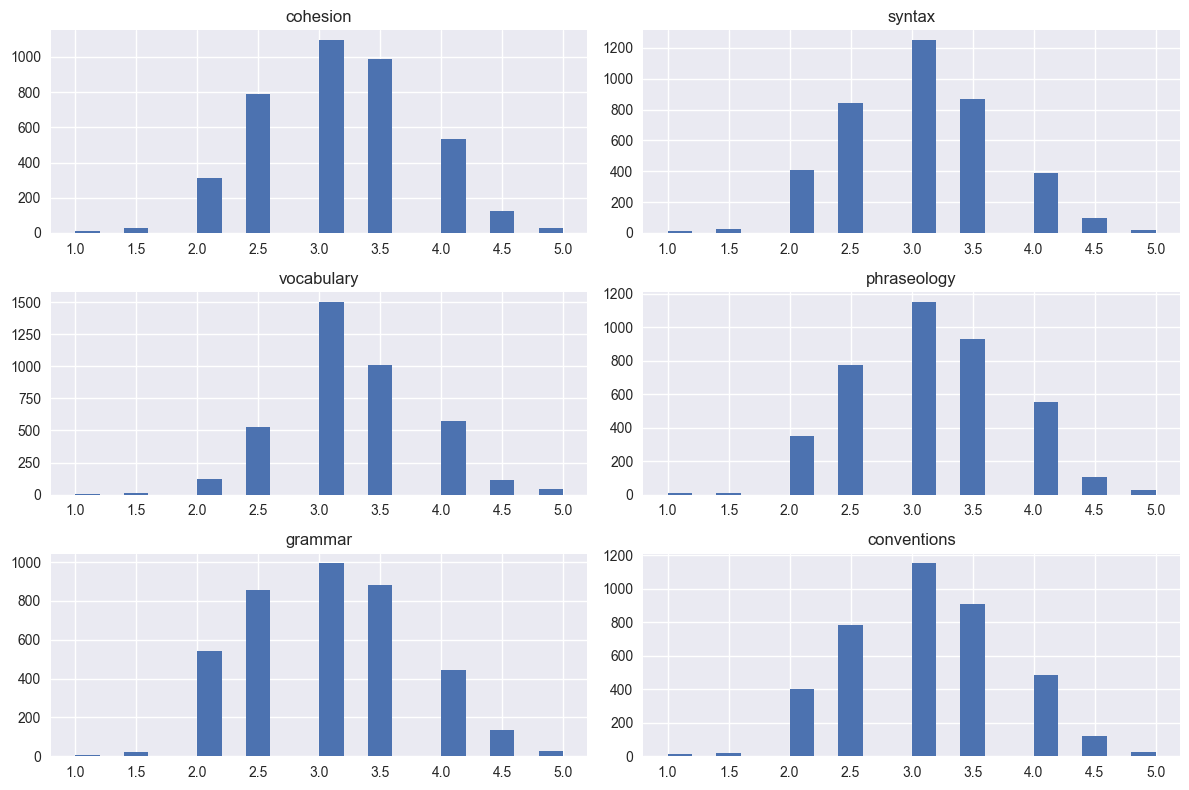

In [11]:
score_columns = ['cohesion', 'syntax', 'vocabulary', 'phraseology', 'grammar', 'conventions']

df[score_columns].hist(figsize=(12,8), bins=20)
plt.tight_layout()
plt.show()


cohesion       3.127077
syntax         3.028254
vocabulary     3.235745
phraseology    3.116850
grammar        3.032856
conventions    3.081053
dtype: float64


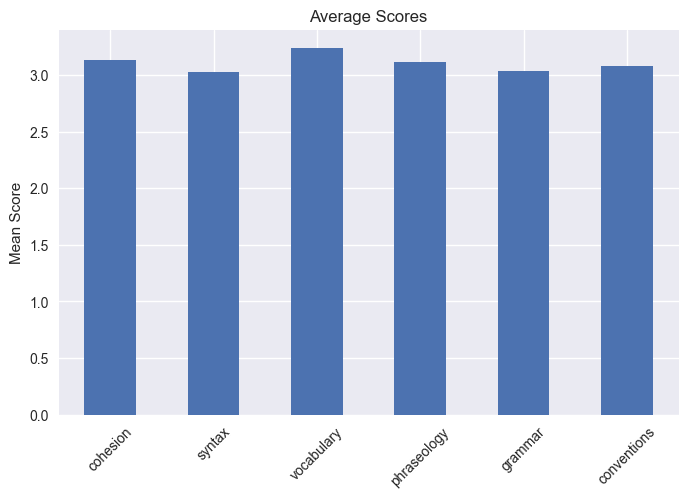

In [12]:
mean_scores = df[score_columns].mean()

print(mean_scores)

mean_scores.plot(kind='bar', figsize=(8,5))
plt.title("Average Scores")
plt.ylabel("Mean Score")
plt.xticks(rotation=45)
plt.show()


             cohesion    syntax  vocabulary  phraseology   grammar  \
cohesion     1.000000  0.695459    0.666151     0.690058  0.638689   
syntax       0.695459  1.000000    0.680562     0.725467  0.709525   
vocabulary   0.666151  0.680562    1.000000     0.735261  0.654852   
phraseology  0.690058  0.725467    0.735261     1.000000  0.719746   
grammar      0.638689  0.709525    0.654852     0.719746  1.000000   
conventions  0.666151  0.700025    0.664292     0.666842  0.673301   

             conventions  
cohesion        0.666151  
syntax          0.700025  
vocabulary      0.664292  
phraseology     0.666842  
grammar         0.673301  
conventions     1.000000  


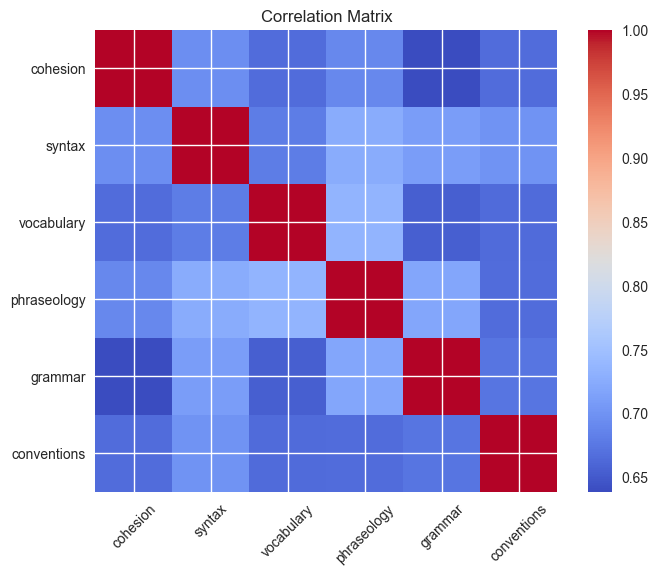

In [13]:
correlation = df[score_columns].corr()

print(correlation)

plt.figure(figsize=(8,6))
plt.imshow(correlation, cmap='coolwarm', interpolation='nearest')
plt.colorbar()
plt.xticks(range(len(score_columns)), score_columns, rotation=45)
plt.yticks(range(len(score_columns)), score_columns)
plt.title("Correlation Matrix")
plt.show()


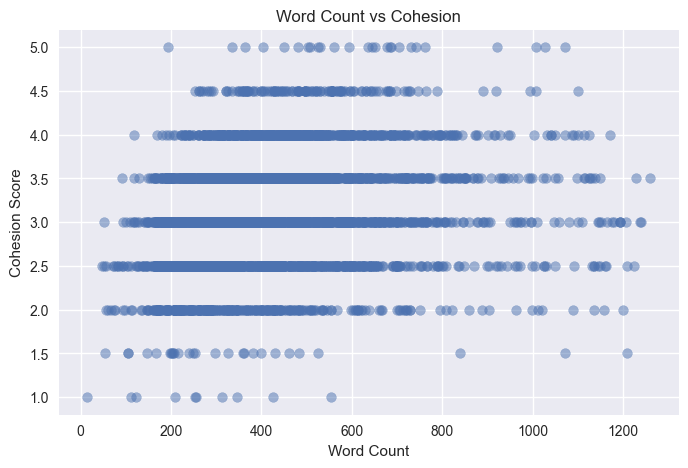

In [14]:
plt.figure(figsize=(8,5))
plt.scatter(df['word_count'], df['cohesion'], alpha=0.5)
plt.xlabel("Word Count")
plt.ylabel("Cohesion Score")
plt.title("Word Count vs Cohesion")
plt.show()


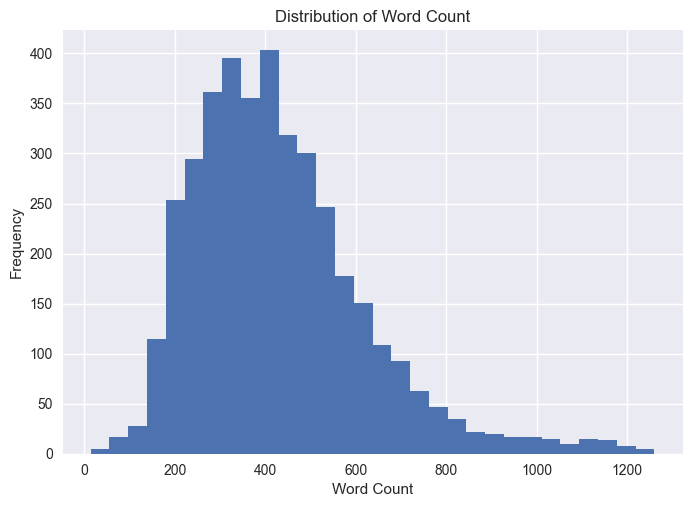

In [15]:
plt.hist(df['word_count'], bins=30)
plt.title("Distribution of Word Count")
plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.show()


In [16]:
scores_array = df[score_columns].values
print(scores_array[:5])


[[3.5 3.5 3.  3.  4.  3. ]
 [2.5 2.5 3.  2.  2.  2.5]
 [3.  3.5 3.  3.  3.  2.5]
 [4.5 4.5 4.5 4.5 4.  5. ]
 [2.5 3.  3.  3.  2.5 2.5]]


In [17]:
print("Mean:", np.mean(scores_array))
print("Median:", np.median(scores_array))
print("Standard Deviation:", np.std(scores_array))
print("Min:", np.min(scores_array))
print("Max:", np.max(scores_array))


Mean: 3.1036393079348845
Median: 3.0
Standard Deviation: 0.6575146068657426
Min: 1.0
Max: 5.0


In [18]:
normalized_scores = (scores_array - np.min(scores_array)) / (np.max(scores_array) - np.min(scores_array))

print(normalized_scores[:5])


[[0.625 0.625 0.5   0.5   0.75  0.5  ]
 [0.375 0.375 0.5   0.25  0.25  0.375]
 [0.5   0.625 0.5   0.5   0.5   0.375]
 [0.875 0.875 0.875 0.875 0.75  1.   ]
 [0.375 0.5   0.5   0.5   0.375 0.375]]


In [19]:
df['overall_score'] = df[score_columns].mean(axis=1)

print(df[['text_id', 'overall_score']].head())


        text_id  overall_score
0  0016926B079C       3.333333
1  0022683E9EA5       2.416667
2  00299B378633       3.000000
3  003885A45F42       4.500000
4  0049B1DF5CCC       2.750000


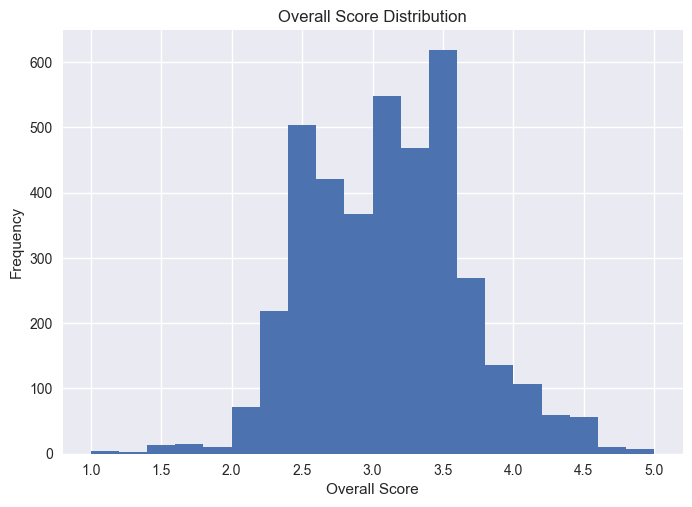

In [20]:
plt.hist(df['overall_score'], bins=20)
plt.title("Overall Score Distribution")
plt.xlabel("Overall Score")
plt.ylabel("Frequency")
plt.show()


In [21]:
top_10 = df.sort_values(by='overall_score', ascending=False).head(10)

print(top_10[['text_id', 'overall_score']])


           text_id  overall_score
2389  B1AFACE6704E       5.000000
1082  52DC3B7C3952       4.916667
258   12E3D52345C6       4.916667
1060  5132328226C2       4.833333
3445  EC2758A5B74E       4.833333
1765  85C54BD4D416       4.833333
104   07CE77EA56C5       4.833333
937   477B00F899E2       4.833333
1206  5D7D1445A7CF       4.750000
3333  E70DD00622DB       4.750000


In [22]:
df.to_csv("cleaned_train.csv", index=False)


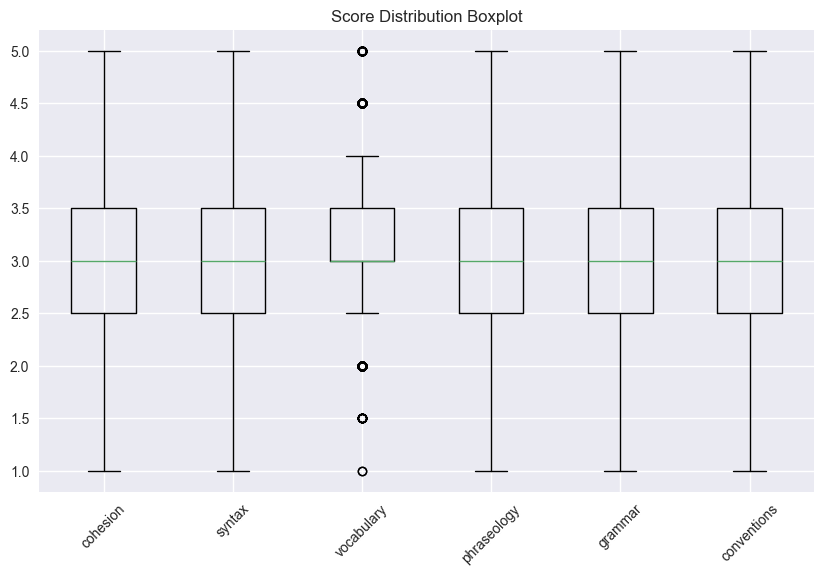

In [23]:
plt.figure(figsize=(10,6))
plt.boxplot([df[col] for col in score_columns], labels=score_columns)
plt.title("Score Distribution Boxplot")
plt.xticks(rotation=45)
plt.show()


In [24]:
df.to_csv("cleaned_train.csv", index=False)